# Stats 21 - HW4: Palmer Penguins, Summaries, and Plots

## Dillon Han

Practice turning a question into a pandas analysis and a clearly explained plot.
The central questions are: **Which records contribute, what does a summary mean,
and what can we learn from comparing groups?**


## Academic Integrity

This homework is practice for building your own understanding. Work through the problems, check your reasoning, and use permitted help to support your learning.

Replace `Dillon Han` to acknowledge the following:

> I, Dillon Han, agree to follow the course academic integrity policies and the Stats 21 AI and Collaboration Policy. My submitted work reflects my own thinking and understanding, and I can explain my code and results.

**Acknowledgments and AI disclosure:** Credit any people or sources you relied on, and disclose any AI assistance (including hints, debugging, or editing). Briefly state which problems they helped with and how, or write "None".

[Your acknowledgments and AI disclosure here.]

---

### Setup and submission

- Use pandas for data preparation, Matplotlib for Part 6, seaborn for Parts 7 and 8, and either pandas plotting or Matplotlib for Part 9.
- Review lectures 13–15 and 17–18.
- Complete the code and short written responses (1–2 sentences are usually enough unless specified otherwise). Use code to calculate requested results rather than hardcoding values.
- Keep `penguins.csv` in the same directory as this notebook. Use this supplied file rather than loading the dataset from seaborn, as this version includes the `year` column.
- Before submitting, restart the kernel and run all cells from top to bottom so all tables, plots, and written responses are visible.
- Export to HTML, print to a letter-sized PDF, and submit the PDF to Gradescope with pages assigned to each question. Submit your completed `.ipynb` file as well.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.precision", 3)


### About the data

Each row represents a single penguin record. `species`, `island`, and `sex` describe groups, and `year` records the study year. Bill length, bill depth, and flipper length are measured in millimeters; body mass is in grams.

The data were collected by Kristen Gorman and the Palmer Station LTER program. See the [Palmer Penguins data dictionary](https://allisonhorst.github.io/palmerpenguins/reference/penguins.html) for details.


In [2]:
penguins = pd.read_csv("penguins.csv")

# Use these four physical measurements for the requested numeric summaries.
measurement_cols = [
    "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"
]
species_order = ["Adelie", "Chinstrap", "Gentoo"]

penguins.head()


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


### Part 1) Inspect the data

Use the original `penguins` table.

a. Display its shape and state what one row represents.

b. Display the column names and data types. Which numeric column records the study year rather than a physical measurement? Why shouldn't data type alone determine which columns belong in a summary of penguin size?

c. Display the number of missing values in each column.

d. Count records by `species` and by `sex`, including missing values (`value_counts(dropna=False)`). Verify that each set of counts adds up to the total number of rows.


In [7]:
# Part 1: inspect the original table and display the requested counts.
print(penguins.shape)
print(penguins.dtypes)
print(penguins.isna().sum())
species_counts = penguins["species"].value_counts(dropna=False)
sex_counts = penguins["sex"].value_counts(dropna=False)

print(species_counts)
print(sex_counts)
print(species_counts.sum() == len(penguins), sex_counts.sum() == len(penguins))

(344, 8)
species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64
sex
male      168
female    165
NaN        11
Name: count, dtype: int64
True True


**Written response:**

year is the study year, not a physical measurement. Data type alone shouldn’t decide what goes in a summary of penguin size, because pandas treats every number the same way. penguins.describe() would report a “mean year” of about 2008.03, since it is a number, but it tells you nothing about how big penguins are.

### Part 2) Missing data: choose rows for the question

Do not modify the original `penguins` DataFrame in place.

a. Create `penguins_clean` by dropping rows missing any of the four `measurement_cols` or `sex` (use `.dropna(subset=...).copy()`). Display its shape and the number of rows removed.

b. Create `penguins_bill` from `penguins` by dropping only rows missing `bill_length_mm`, `bill_depth_mm`, or `species`, keeping all columns. Display its shape and how many more records it retains than `penguins_clean`.

c. For a plot of bill length versus bill depth colored by species, which subset is more appropriate? Explain why a missing value for `sex` should or should not exclude a record from this plot.

*Note: `penguins_clean` is only for comparison here. In the parts that follow, filter `penguins` (or use `penguins_bill` where specified) based only on the variables needed for that question.*


In [9]:
# Part 2: construct the two subsets and compare their row counts.
penguins_clean = penguins.dropna(subset=measurement_cols + ["sex"]).copy()

print(penguins_clean.shape)
print(len(penguins) - len(penguins_clean))

penguins_bill = penguins.dropna(
    subset=["bill_length_mm", "bill_depth_mm", "species"]
).copy()

print(penguins_bill.shape)
print(len(penguins_bill) - len(penguins_clean))

(333, 8)
11
(342, 8)
9


**Written response:**

penguins_bill is the better subset for a plot of bill length versus bill depth colored by species. The plot only uses bill_length_mm, bill_depth_mm and species, and a point can be drawn whenever those three are present.

A missing sex value shouldn’t exclude a record from this plot, because sex isn’t shown in the graph. Using penguins_clean would throw away 9 valid bill measurements. 


### Part 3) Numeric summaries and a small wrangling task

Use `penguins`, retaining rows with missing values.

a. Use `.describe()` on `measurement_cols` to show the count, mean, standard deviation, minimum, quartiles, and maximum. Explain what `count` represents and why it can differ from the total number of rows.

b. Compute the mean and standard deviation of `measurement_cols` within each species.

c. Add a `body_mass_kg` column to `penguins` by converting grams to kilograms. Filter for Gentoo penguins from 2008 with a recorded body mass. Display the total number of matching records, and show `species`, `island`, `year`, and `body_mass_kg` for the five heaviest penguins sorted from heaviest to lightest.


In [11]:
# Part 3: summarize measurements, create kilograms, then filter/select/sort.
print(penguins[measurement_cols].describe())

print(penguins.groupby("species")[measurement_cols].agg(["mean", "std"]))

penguins["body_mass_kg"] = penguins["body_mass_g"] / 1000

gentoo_2008 = penguins[
    (penguins["species"] == "Gentoo")
    & (penguins["year"] == 2008)
    & penguins["body_mass_kg"].notna()
]

print(len(gentoo_2008))

(gentoo_2008
    .sort_values("body_mass_kg", ascending=False)
    [["species", "island", "year", "body_mass_kg"]]
    .head(5))

       bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count         342.000        342.000            342.000      342.000
mean           43.922         17.151            200.915     4201.754
std             5.460          1.975             14.062      801.955
min            32.100         13.100            172.000     2700.000
25%            39.225         15.600            190.000     3550.000
50%            44.450         17.300            197.000     4050.000
75%            48.500         18.700            213.000     4750.000
max            59.600         21.500            231.000     6300.000
          bill_length_mm        bill_depth_mm        flipper_length_mm         \
                    mean    std          mean    std              mean    std   
species                                                                         
Adelie            38.791  2.663        18.346  1.217           189.954  6.539   
Chinstrap         48.834  3.339        18.421  1.135   

,species,island,year,body_mass_kg
229,Gentoo,Biscoe,2008,6.00
231,Gentoo,Biscoe,2008,5.95
219,Gentoo,Biscoe,2008,5.80
227,Gentoo,Biscoe,2008,5.80
193,Gentoo,Biscoe,2008,5.70


**Written response:**

count is the number of non-missing values in each column, so it’s the number of penguins each statistic is actually computed from. It can be smaller than the number of rows because .describe() skips NaN values instead of counting them.

### Part 4) Two-way grouped summaries

Use `penguins` and group by `species` and `sex`, keeping missing-sex groups with `groupby(..., dropna=False)`.

a. Produce a summary table with one row per species/sex combination that includes the total row count (`n_penguins`, using `size`) and the mean and nonmissing count (`count`) for each of the four `measurement_cols`.

b. Verify that `n_penguins` sums to the total number of rows in `penguins`. For one of the unknown-sex groups, compare `n_penguins` with its nonmissing `body_mass_g` count. Explain why they differ and which count serves as the denominator when computing mean body mass.

c. Among groups with recorded sex, identify the species/sex group with the largest mean body mass and display its summary row. Does having the largest group mean imply that every penguin in that group is heavier than every penguin in the other groups? Explain briefly.


In [15]:
# Part 4: keep unknown-sex groups and distinguish size from count.
agg_spec = {"n_penguins": ("species", "size")}
for col in measurement_cols:
    agg_spec[f"{col}_mean"] = (col, "mean")
    agg_spec[f"{col}_count"] = (col, "count")

summary = (
    penguins
    .groupby(["species", "sex"], dropna=False)   # keep unknown-sex groups
    .agg(**agg_spec)
    .reset_index()
)
display(summary)

print("Sum of n_penguins:", summary["n_penguins"].sum())
print("Rows in penguins:", len(penguins))
print("Match:", summary["n_penguins"].sum() == len(penguins))

unknown_sex = summary[summary["sex"].isna()]
display(unknown_sex[["species", "sex", "n_penguins",
                     "body_mass_g_count", "body_mass_g_mean"]])

known_sex = summary[summary["sex"].notna()]
heaviest_group = known_sex.loc[[known_sex["body_mass_g_mean"].idxmax()]]
display(heaviest_group)

display(penguins.groupby(["species", "sex"])["body_mass_g"].agg(["min", "max"]))

,species,sex,n_penguins,bill_length_mm_mean,bill_length_mm_count,bill_depth_mm_mean,bill_depth_mm_count,flipper_length_mm_mean,flipper_length_mm_count,body_mass_g_mean,body_mass_g_count
0,Adelie,female,73,37.258,73,17.622,73,187.795,73,3368.836,73
1,Adelie,male,73,40.390,73,19.073,73,192.411,73,4043.493,73
2,Adelie,NaN,6,37.840,5,18.320,5,185.600,5,3540.000,5
3,Chinstrap,female,34,46.574,34,17.588,34,191.735,34,3527.206,34
4,Chinstrap,male,34,51.094,34,19.253,34,199.912,34,3938.971,34
5,Gentoo,female,58,45.564,58,14.238,58,212.707,58,4679.741,58
6,Gentoo,male,61,49.474,61,15.718,61,221.541,61,5484.836,61
7,Gentoo,NaN,5,45.625,4,14.550,4,215.750,4,4587.500,4


Sum of n_penguins: 344
Rows in penguins: 344
Match: True


,species,sex,n_penguins,body_mass_g_count,body_mass_g_mean
2,Adelie,NaN,6,5,3540.0
7,Gentoo,NaN,5,4,4587.5


,species,sex,n_penguins,bill_length_mm_mean,bill_length_mm_count,bill_depth_mm_mean,bill_depth_mm_count,flipper_length_mm_mean,flipper_length_mm_count,body_mass_g_mean,body_mass_g_count
6,Gentoo,male,61,49.474,61,15.718,61,221.541,61,5484.836,61


min     max
species   sex                   
Adelie    female  2850.0  3900.0
          male    3325.0  4775.0
Chinstrap female  2700.0  4150.0
          male    3250.0  4800.0
Gentoo    female  3950.0  5200.0
          male    4750.0  6300.0

**Written response:**

The Adelie unknown-sex group has an n_penguins of 6 but only 5 non-missing body_mass_g values, because one of its rows has no measurements at all. size counts every row, while count skips the NaN, so the mean body mass is divided by the 5 recorded values, not 6.

No. A mean shows where the middle of a group falls, not where each penguin falls. The ranges overlap: the lightest Gentoo male weighs 4750 g, which is less than some Gentoo females (up to 5200 g), Chinstrap males (up to 4800 g) and Adelie males (up to 4775 g).

### Part 5) Correlations and Simpson's paradox

Use `penguins_bill` and `measurement_cols`.

a. Compute the Pearson correlation matrix for the four measurements, first across all penguins pooled together, and then separately within each species (`groupby("species")[measurement_cols].corr()`).

b. Focus on **bill length and bill depth**. Create a compact summary table showing their pooled correlation, their correlation within each species, and the number of paired records used in each calculation.

c. Compare the signs of the correlations. A *Simpson's paradox reversal* occurs when the pooled association has the opposite sign from the association within each individual group. State whether your results show this reversal, citing the correlation values.


In [16]:
# Part 5: show the correlation matrices and a compact bill-pair comparison.
pooled_corr = penguins[measurement_cols].corr()
display(pooled_corr)

species_corr = penguins.groupby("species")[measurement_cols].corr()
display(species_corr)

bill = penguins.dropna(subset=["bill_length_mm", "bill_depth_mm"])

rows = [{"group": "All (pooled)",
         "r_bill_length_depth": bill["bill_length_mm"].corr(bill["bill_depth_mm"]),
         "n_pairs": len(bill)}]
for species, group in bill.groupby("species"):
    rows.append({"group": species,
                 "r_bill_length_depth": group["bill_length_mm"].corr(group["bill_depth_mm"]),
                 "n_pairs": len(group)})

bill_corr_summary = pd.DataFrame(rows)
display(bill_corr_summary)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.235,0.656,0.595
bill_depth_mm,-0.235,1.000,-0.584,-0.472
flipper_length_mm,0.656,-0.584,1.000,0.871
body_mass_g,0.595,-0.472,0.871,1.000


bill_length_mm  bill_depth_mm  flipper_length_mm  \
species                                                                         
Adelie    bill_length_mm              1.000          0.391              0.326   
          bill_depth_mm               0.391          1.000              0.308   
          flipper_length_mm           0.326          0.308              1.000   
          body_mass_g                 0.549          0.576              0.468   
Chinstrap bill_length_mm              1.000          0.654              0.472   
          bill_depth_mm               0.654          1.000              0.580   
          flipper_length_mm           0.472          0.580              1.000   
          body_mass_g                 0.514          0.604              0.642   
Gentoo    bill_length_mm              1.000          0.643              0.661   
          bill_depth_mm               0.643          1.000              0.707   
          flipper_length_mm           0.661          0.707              1.000   
          body_mass_g                 0.669          0.719              0.703   

                             body_mass_g  
species                                   
Adelie    bill_length_mm           0.549  
          bill_depth_mm            0.576  
          flipper_length_mm        0.468  
          body_mass_g              1.000  
Chinstrap bill_length_mm           0.514  
          bill_depth_mm            0.604  
          flipper_length_mm        0.642  
          body_mass_g              1.000  
Gentoo    bill_length_mm           0.669  
          bill_depth_mm            0.719  
          flipper_length_mm        0.703  
          body_mass_g              1.000

,group,r_bill_length_depth,n_pairs
0,All (pooled),-0.235,342
1,Adelie,0.391,151
2,Chinstrap,0.654,68
3,Gentoo,0.643,123


**Written response:**

c. Yes, this is a Simpson’s paradox reversal. Across all penguins, bill length and bill depth have a weak negative correlation (r = −0.235), but within each species the correlation is positive: Adelie r = 0.391, Chinstrap r = 0.654, Gentoo r = 0.643. The pooled correlation turns negative because Gentoo penguins have long, shallow bills and Adelie penguins have short, deep ones, so mixing the species hides the positive relationship inside each one.

## Plots: make the analysis visible

For Parts 6–9:
- Give each figure a descriptive title, axis labels with units, and a legend where appropriate.
- Use comparable axes when comparing panels.
- Report the number of included and excluded records for each plot, dropping only rows that are missing variables required for that specific plot.


### Part 6) Matplotlib histograms of body mass by species

Use rows of `penguins` with nonmissing `body_mass_g` and `species`.

a. Use `plt.subplots(1, 3, ...)` and `ax.hist(...)` to create one panel per species in `species_order`. Share the x- and y-axes and pass the same explicit bin edges (e.g., `range(2500, 6501, 500)`) to all three panels.

b. Plot counts, label body mass in grams, and include each species' sample size ($n$) in its panel title. Report the total number of included and excluded records.

c. In two sentences, compare the distributions across species and explain why a taller histogram can reflect sample size as well as distribution shape. If you set `density=True`, would the total area of the bars or the sum of the bar heights equal 1?


342
2


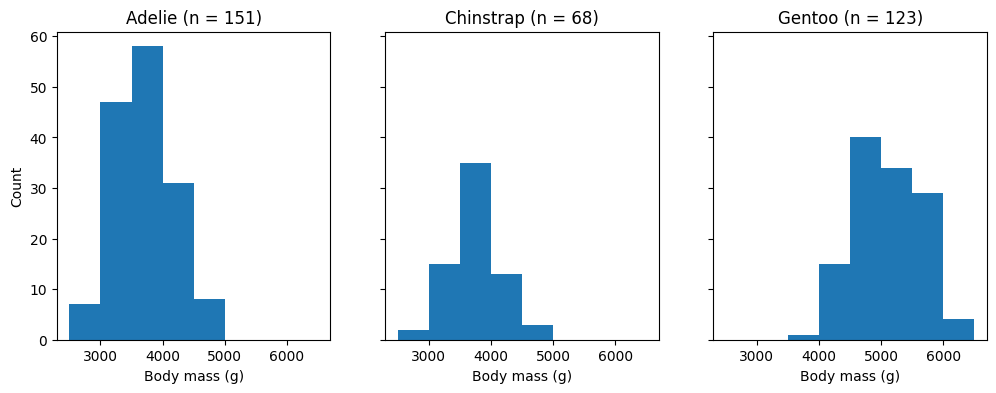

In [18]:
# Part 6: choose records, then build three Matplotlib histogram panels.
mass = penguins.dropna(subset=["body_mass_g", "species"])
mass = penguins.dropna(subset=["body_mass_g", "species"])
print(len(mass))
print(len(penguins) - len(mass))

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, species in zip(axes, species_order):
    values = mass.loc[mass["species"] == species, "body_mass_g"]
    ax.hist(values, bins=range(2500, 6501, 500))
    ax.set_title(f"{species} (n = {len(values)})")
    ax.set_xlabel("Body mass (g)")
axes[0].set_ylabel("Count")
plt.show()

**Written response:**

Adelie and Chinstrap penguins have similar distributions, Gentoo penguins are shifted clearly higher, on a count scale, bar height depends on how many penguins are in the group as well as on the shape. 

With density=True, the total area of the bars equals 1, not the sum of their heights. Each bar’s height is divided by the bin width (500 g here), so the heights sum to 1/500 = 0.002.

### Part 7) Seaborn boxplots of flipper length

Use rows of `penguins` with nonmissing `flipper_length_mm` and `species`.

a. Create a Matplotlib `Axes` and pass it to `sns.boxplot(..., ax=ax)` with `species` (in `species_order`) on the x-axis and `flipper_length_mm` on the y-axis. Report the included/excluded record counts and sample sizes by species.

b. In 2–3 sentences, explain what the box and center line represent, and compare the medians and middle-50% spreads across species. Does a point plotted beyond the whiskers necessarily indicate a data error? Explain briefly.


Included: 342
Excluded: 2
species
Adelie       151
Chinstrap     68
Gentoo       123
Name: count, dtype: int64


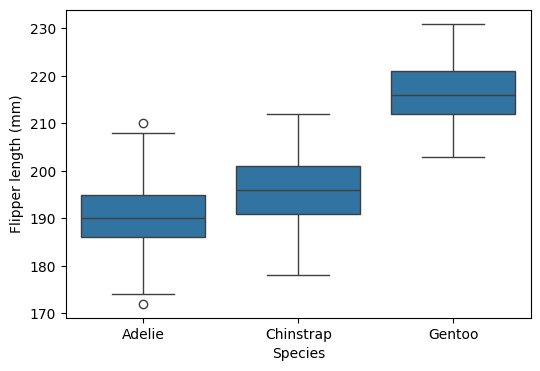

In [19]:
# Part 7: draw seaborn boxplots on a Matplotlib Axes.
flipper = penguins.dropna(subset=["species", "flipper_length_mm"])
print("Included:", len(flipper))
print("Excluded:", len(penguins) - len(flipper))
print(flipper["species"].value_counts().reindex(species_order))

fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=flipper, x="species", y="flipper_length_mm", order=species_order, ax=ax)
ax.set_xlabel("Species")
ax.set_ylabel("Flipper length (mm)")
plt.show()

**Written response:**

The box covers the middle 50% of flipper lengths, from the 25th to the 75th percentile, and the line inside it is the median. Gentoo penguins have by far the longest flippers, followed by Chinstrap and Adelie, with the middle-50% spreads being very similar across species.

A point beyond the whiskers isn’t necessarily a data error, it only means the value is more than 1.5 × the box height (the IQR) beyond the edge of the box.

### Part 8) Scatterplot and fitted lines: bill length versus bill depth

Use `penguins_bill`.

a. Plot `bill_length_mm` (x) versus `bill_depth_mm` (y), colored by `species`, with a separate linear regression line for each species. Include a legend and report the number of included and excluded records.

*Hint: `sns.lmplot(data=..., x=..., y=..., hue="species", ci=None)` plots both the points and fitted lines. Because `lmplot` creates its own figure-level `FacetGrid`, use `g.set_axis_labels(...)` and `g.figure.suptitle(...)` to label the plot (or loop over species with `sns.regplot`).*

b. In 3–4 sentences, explain what a point and a fitted line represent. Connect the slopes of the within-species lines to your correlations in Part 5, and use the relative positions of the three species clusters to explain why the pooled correlation has the opposite sign. Does this plot show that changing a penguin's bill length causes its bill depth to change?


Included: 342
Excluded: 2


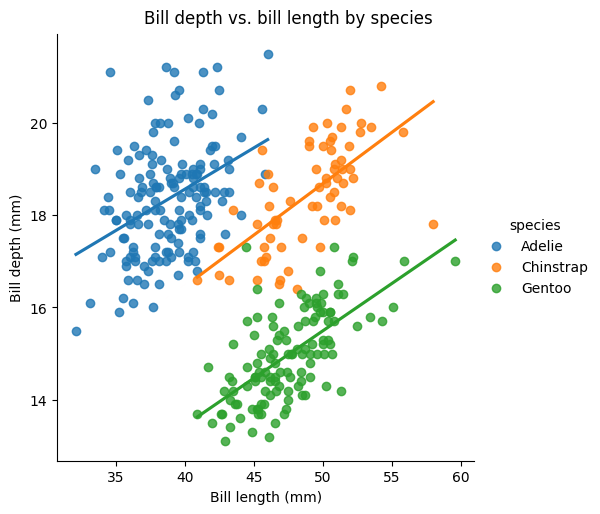

In [20]:
# Part 8: draw paired measurements and separate fitted lines by species.
print("Included:", len(penguins_bill))
print("Excluded:", len(penguins) - len(penguins_bill))

g = sns.lmplot(data=penguins_bill, x="bill_length_mm", y="bill_depth_mm",
               hue="species", hue_order=species_order, ci=None)
g.set_axis_labels("Bill length (mm)", "Bill depth (mm)")
g.figure.suptitle("Bill depth vs. bill length by species", y=1.02)
plt.show()

**Written response:**

Each point is one penguin’s bill length and depth, and each line is that species’ least-squares fit, showing its typical bill depth at a given bill length. All three lines slope upward, which matches the positive within-species correlations (Adelie r = 0.391, Chinstrap r = 0.654, Gentoo r = 0.643). The pooled correlation is negative (r = −0.235) because Adelie penguins cluster in the upper left with short, deep bills and Gentoo penguins in the lower right with long, shallow bills, so a single line through all the points slopes downward.

The plot doesn’t show causation, it’s observational data, so it shows only that longer bills tend to go with deeper bills within a species, probably because both increase with a penguin’s overall size.

### Part 9) Stacked bars: recorded sex proportions by species

Create `penguins_sex` from `penguins` by keeping rows with nonmissing `species` and `sex`.

a. Use `pd.crosstab(...)` to create a species-by-sex count table, then normalize each row to proportions using `.div(..., axis=0)`. Display both tables and verify that each row of proportions sums to 1.

b. Create a stacked bar chart in `species_order` showing the male and female proportions for each species (using `.plot.bar(stacked=True, ax=ax)` or `ax.bar(..., bottom=...)`). Label the y-axis as a proportion and include a legend.

c. Report the number of included and excluded records per species, and include the sample sizes ($n$) in your chart labels or title. Briefly compare the sex proportions across species, and explain why bars of equal total height (1.0) do not imply equal sample sizes.

d. In one sentence, explain what would happen if you reset the index of your 3-row count table and passed it directly to `sns.countplot(data=..., x="species")`.


sex,female,male
species,,
Adelie,73,73
Chinstrap,34,34
Gentoo,58,61


sex,female,male
species,,
Adelie,0.500,0.500
Chinstrap,0.500,0.500
Gentoo,0.487,0.513


species
Adelie       1.0
Chinstrap    1.0
Gentoo       1.0
dtype: float64


,included,excluded
species,,
Adelie,146,6
Chinstrap,68,0
Gentoo,119,5


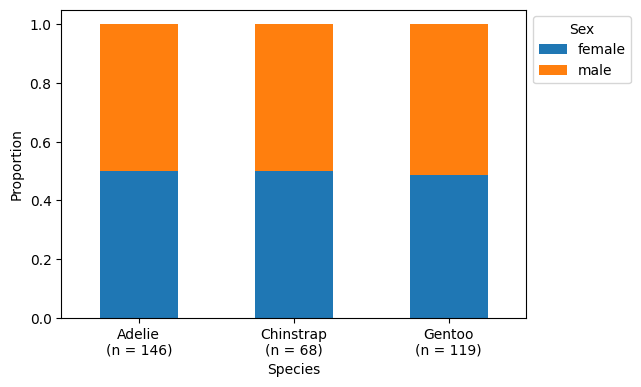

In [ ]:
# Part 9: calculate counts and proportions before drawing the stacked bars.
penguins_sex = penguins.dropna(subset=["species", "sex"]).copy()

counts = pd.crosstab(penguins_sex["species"], penguins_sex["sex"]).reindex(species_order)
props = counts.div(counts.sum(axis=1), axis=0)
display(counts)
display(props.round(3))
print(props.sum(axis=1))

n_total = penguins["species"].value_counts().reindex(species_order)
n_kept = counts.sum(axis=1)
display(pd.DataFrame({"included": n_kept, "excluded": n_total - n_kept}))

fig, ax = plt.subplots(figsize=(6, 4))
props.plot.bar(stacked=True, ax=ax)
ax.set_xticklabels([f"{s}\n(n = {n})" for s, n in n_kept.items()], rotation=0)
ax.set_xlabel("Species")
ax.set_ylabel("Proportion")
ax.legend(title="Sex", bbox_to_anchor=(1, 1), loc="upper left")
plt.show()

**Written response:**

The sex ratio is nearly equal in every species: exactly 50/50 for Adelie and Chinstrap, and 48.7% female / 51.3% male for Gentoo. Every bar reaches 1.0 because each one shows proportions within its own species, so the bar height no longer reflects group size. Adelie has more than twice as many penguins as Chinstrap (146 vs. 68), even though their bars look identical.

d. sns.countplot counts rows, so it would ignore the female and male count columns and draw three bars that are each 1 tall, one per row of the table.

### Before submitting

Restart the kernel and run all cells. Make sure all tables, figures, and written responses are visible, and double-check that you completed the academic integrity acknowledgment at the top of the notebook.

Useful references: [pandas aggregation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.agg.html),
[pandas correlations](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html),
[Matplotlib subplots](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html),
and [seaborn regression plots](https://seaborn.pydata.org/generated/seaborn.lmplot.html).
